# V2 kayitli sonuclar — salt okuma; completed fiziksel kabul degildir.


Grup: completed | completed fiziksel kabul degildir


,experiment_id,scenario_id,state,controls,calculation,k,MC_standard_error,duration_s,fields_npz,summary_json,physical_acceptance,statistical_convergence
0,V2-STAGE_128_OGRENCI_04-0001,4283e9eab852b69aedfe68db62165850baba6407a7e84d...,completed,{'u235_enrichment_wt_percent': 2.1937544157697...,"{'particles_per_generation': 80000, 'batches':...",1.102718,0.000182,7223.487819,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
1,V2-STAGE_128_OGRENCI_04-0002,3562cfaeeb41b73276819a4ccaa177052cad099b03d010...,completed,{'u235_enrichment_wt_percent': 1.8187544157697...,"{'particles_per_generation': 80000, 'batches':...",1.210051,0.000194,6459.565212,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
2,V2-STAGE_128_OGRENCI_04-0003,e31572cb99e02f894ad2bf55195f3d448b9039cf710002...,completed,{'u235_enrichment_wt_percent': 2.5687544157697...,"{'particles_per_generation': 80000, 'batches':...",1.283900,0.000184,6023.488126,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
3,V2-STAGE_128_OGRENCI_04-0004,19a778c753c32d0600034b5d07bed6123742e71a894640...,completed,{'u235_enrichment_wt_percent': 1.6312544157697...,"{'particles_per_generation': 80000, 'batches':...",1.119762,0.000189,6923.854482,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
4,V2-STAGE_128_OGRENCI_04-0005,f39152b7c5c182bc6451b44f843137218bc2b41b7d3ad1...,completed,{'u235_enrichment_wt_percent': 2.3812544157697...,"{'particles_per_generation': 80000, 'batches':...",1.206163,0.000202,6299.280296,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
5,V2-STAGE_128_OGRENCI_04-0006,9ad69885da838cf31c04d23514013c5aa3542c22a4d8b9...,completed,{'u235_enrichment_wt_percent': 2.0062544157697...,"{'particles_per_generation': 80000, 'batches':...",1.124957,0.000186,998.388490,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
6,V2-STAGE_128_OGRENCI_04-0007,ab3774f64d7f91bc8efa3b815dd4be34a297bc6e98590c...,completed,{'u235_enrichment_wt_percent': 2.7562544157697...,"{'particles_per_generation': 80000, 'batches':...",1.174474,0.000195,932.947466,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
7,V2-STAGE_128_OGRENCI_04-0008,0cdebcbfb685259224ff135141d6ab7d02f7bde578620d...,completed,{'u235_enrichment_wt_percent': 3.0375044157697...,"{'particles_per_generation': 80000, 'batches':...",1.131488,0.000196,906.471105,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
8,V2-STAGE_128_OGRENCI_04-0009,91397390a1a307284397c6635d8cc23bae4fc272173c4c...,completed,{'u235_enrichment_wt_percent': 2.2875044157697...,"{'particles_per_generation': 80000, 'batches':...",0.928548,0.000187,916.257450,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
9,V2-STAGE_128_OGRENCI_04-0010,00a84f249527943d4f92aaca7b41036eb11a49fb3de76b...,completed,{'u235_enrichment_wt_percent': 1.9125044157697...,"{'particles_per_generation': 80000, 'batches':...",0.710622,0.000162,944.033932,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required


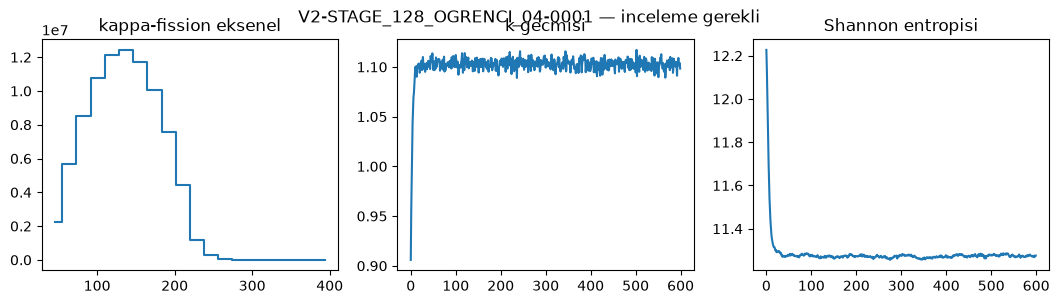

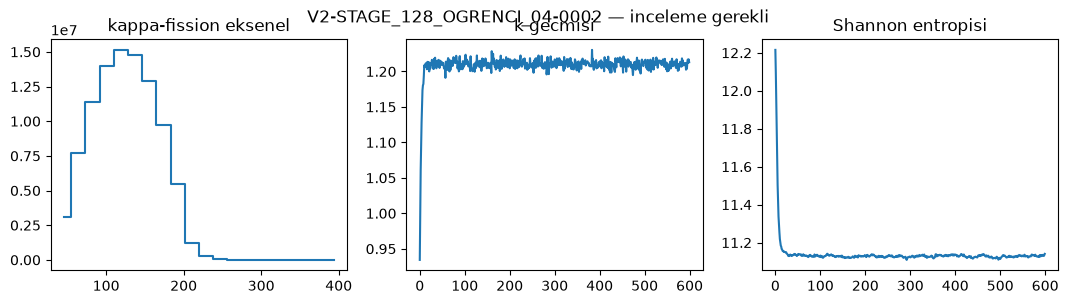

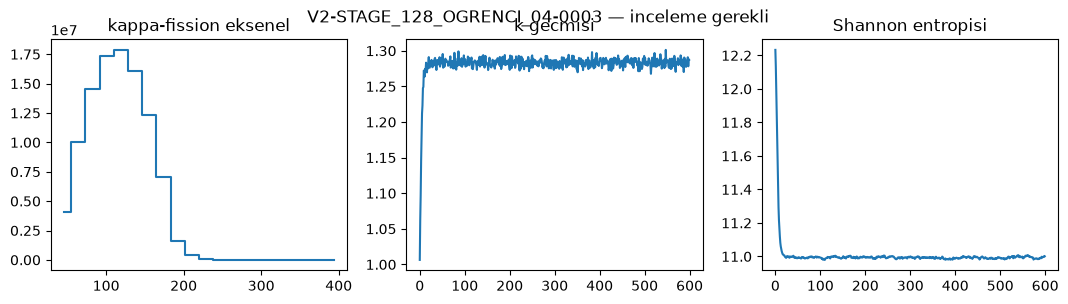

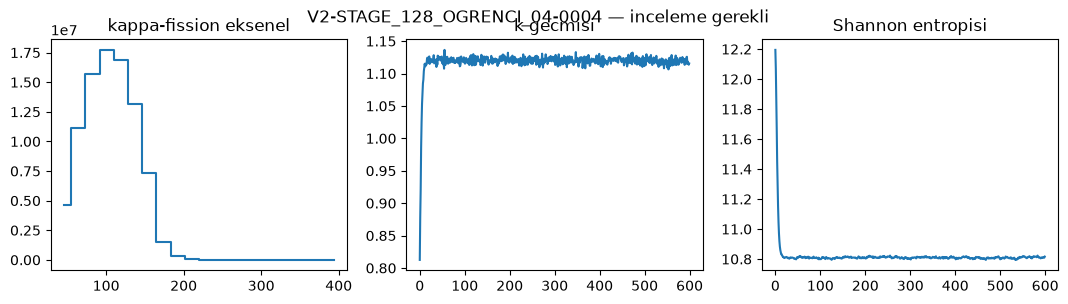

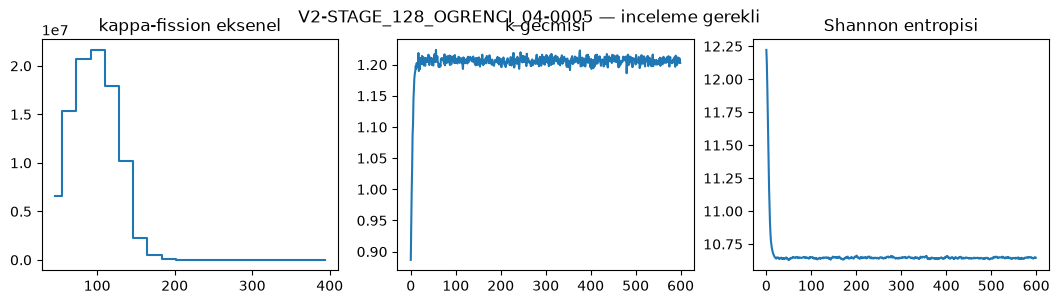

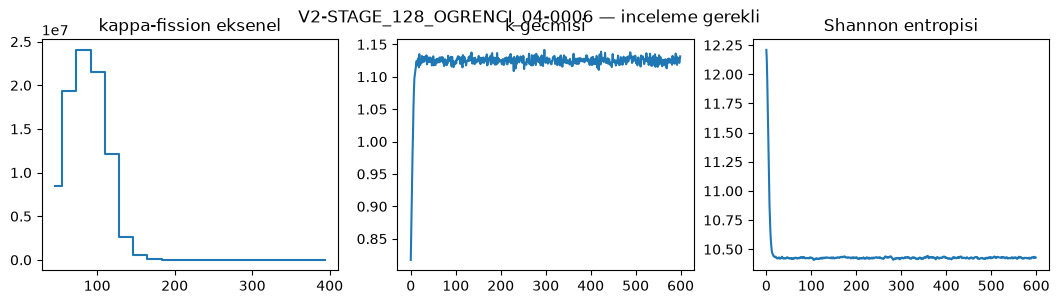

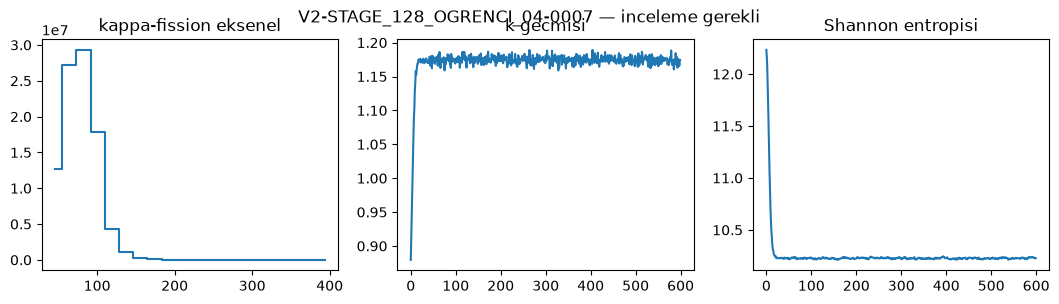

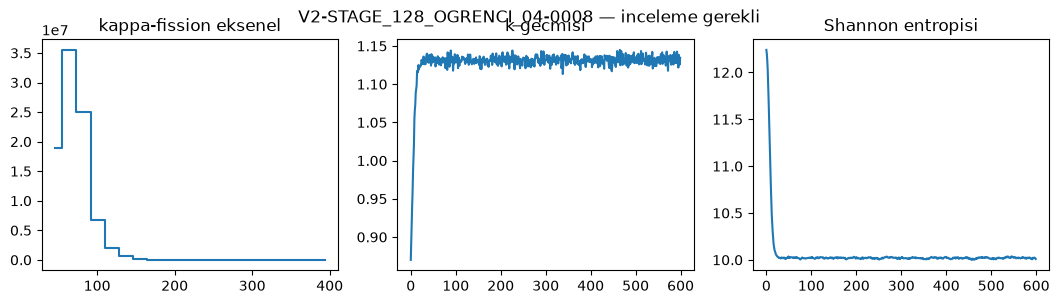

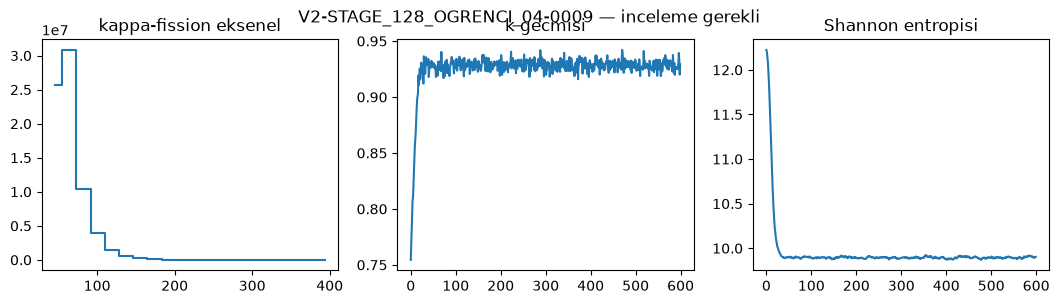

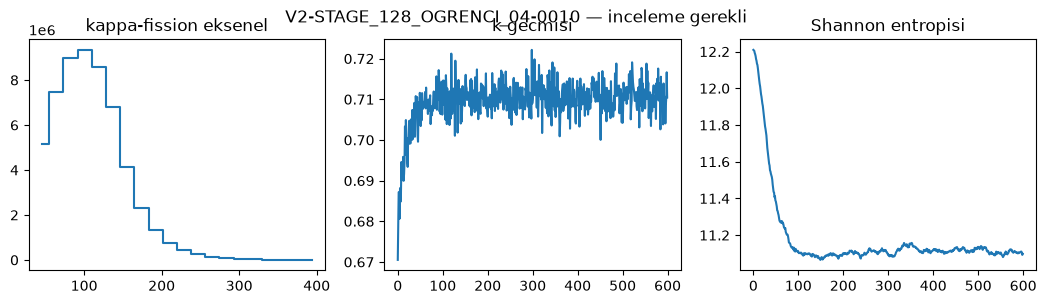

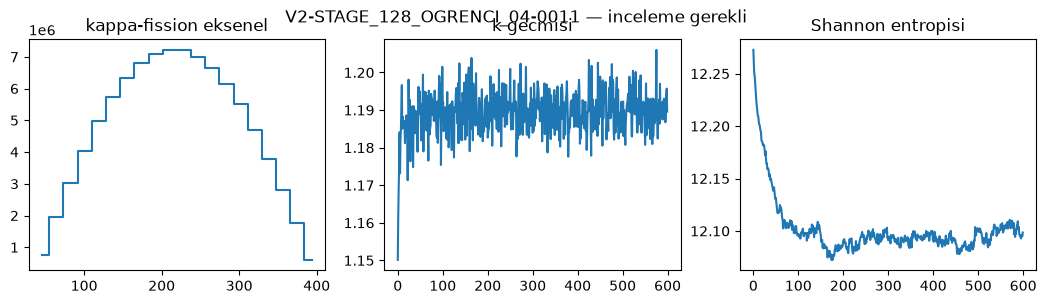

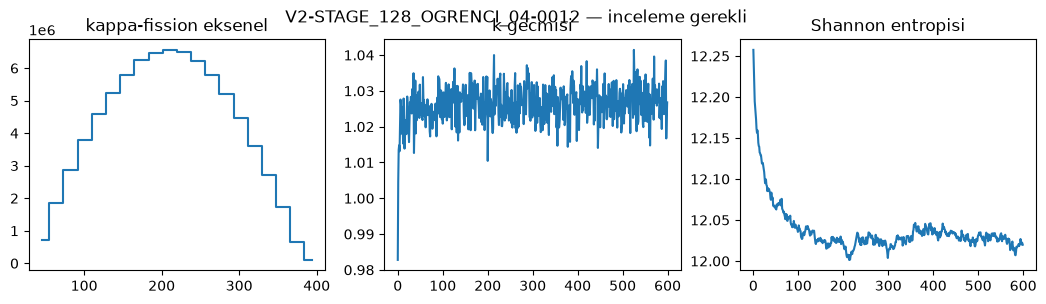

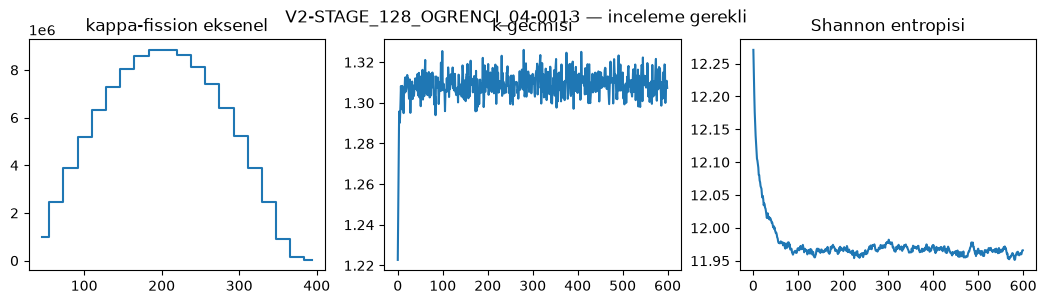

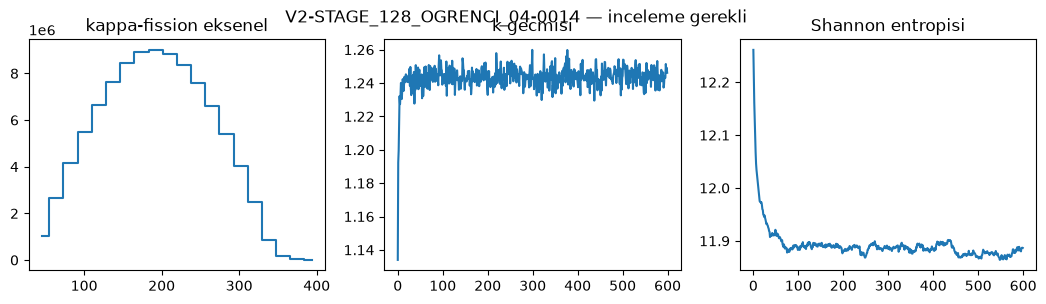

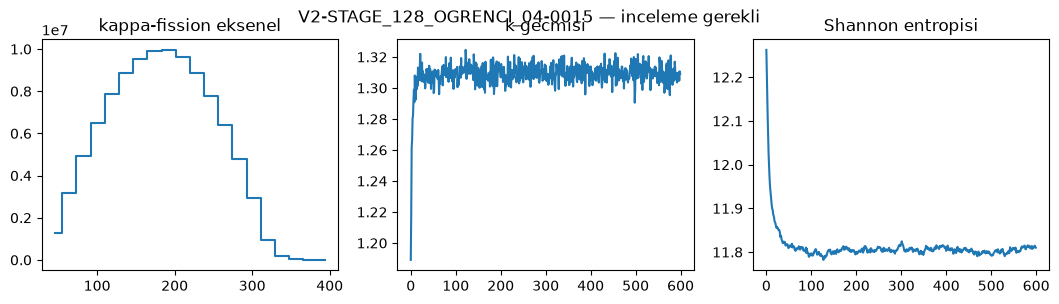

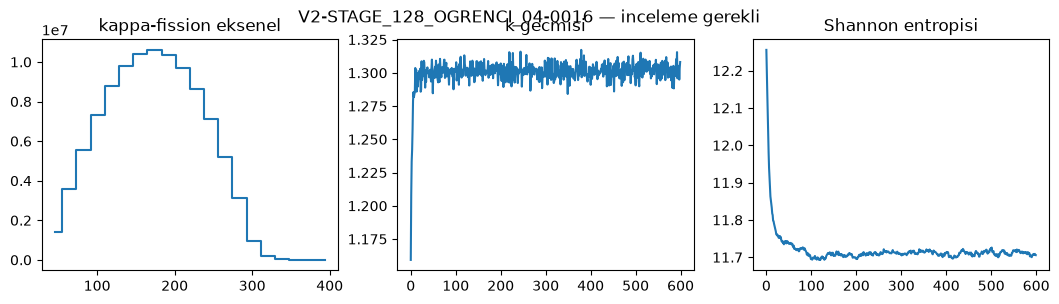

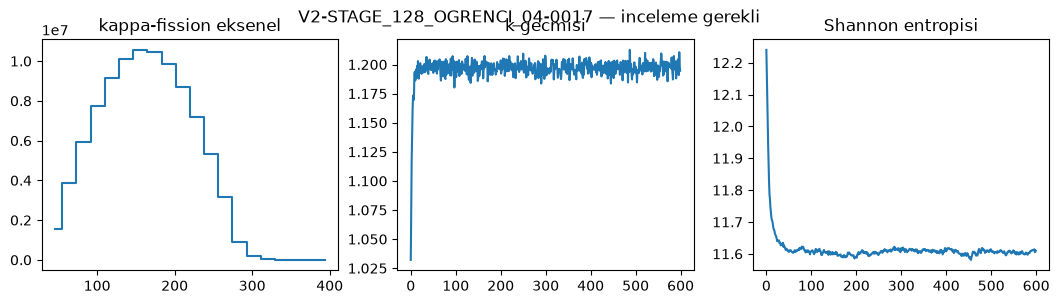

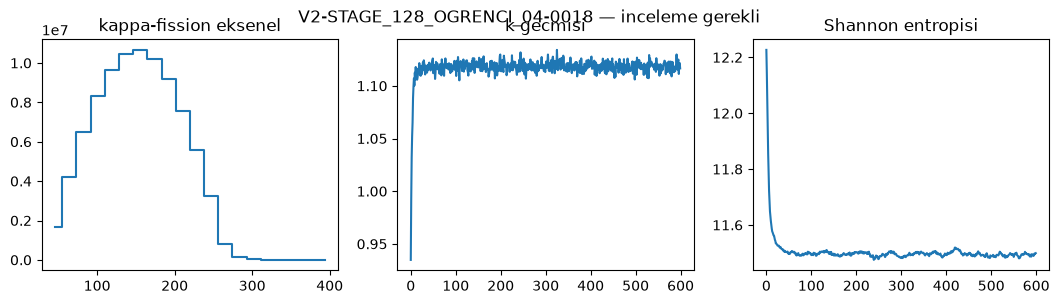

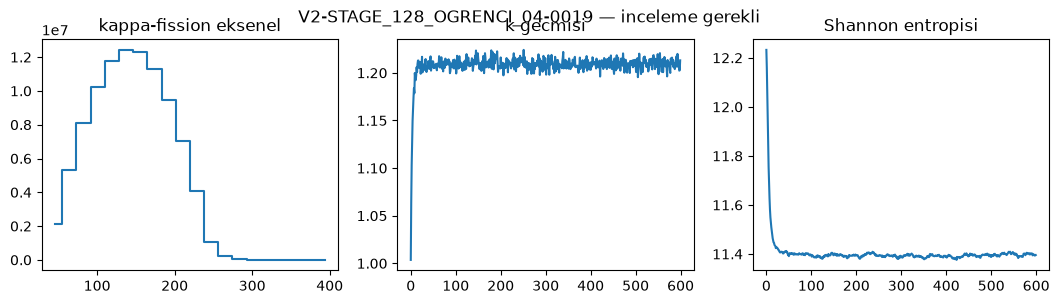

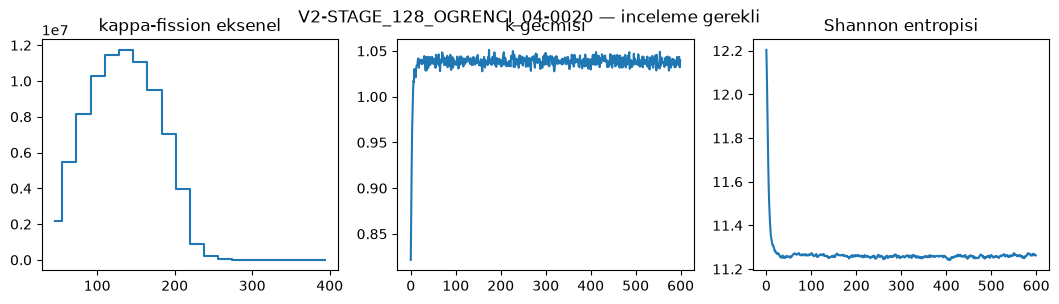

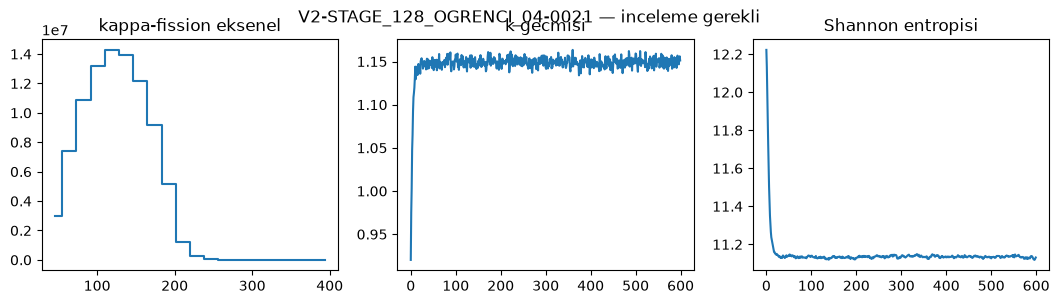

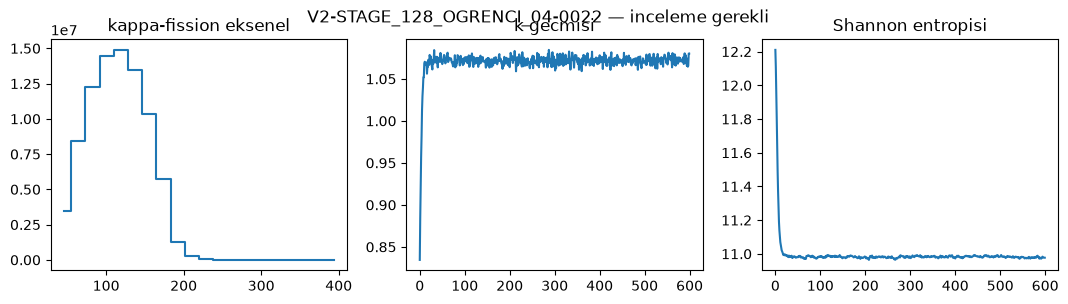

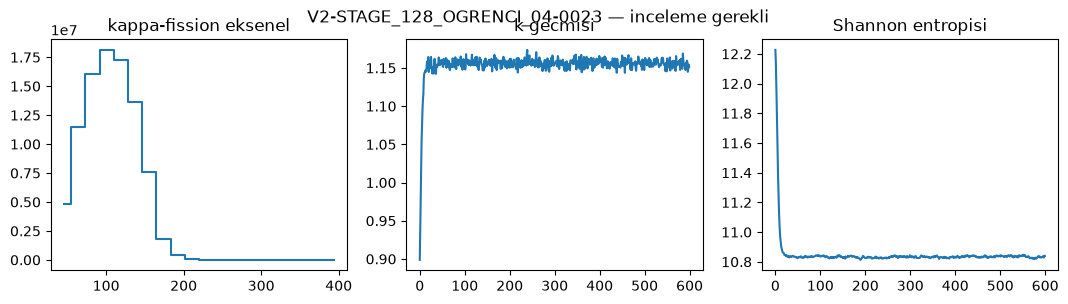

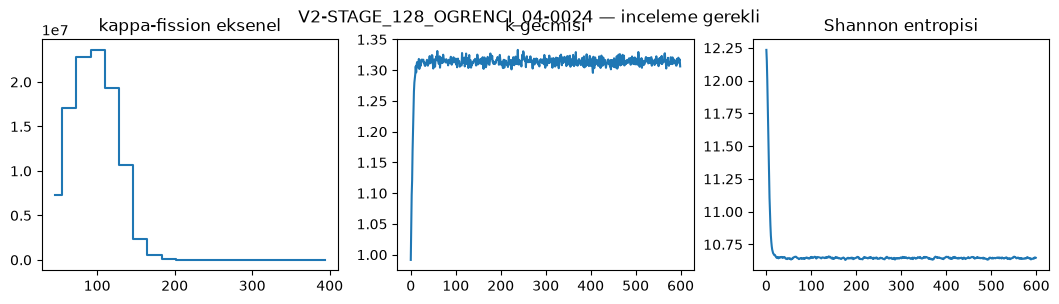

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import json, sys
PACKAGE = Path.cwd().resolve()
PROJECT = next(p for p in (PACKAGE, *PACKAGE.parents) if (p / "src/reactor_pipeline/v2_students.py").is_file())
sys.path.insert(0, str(PROJECT / "src"))
from reactor_pipeline import v2_student_runner, v2_students
assert PACKAGE.name == "v2_stage_128_ogrenci_04_beavrs_v2_pilot_scope_v1"
info = v2_students.verify_package(PACKAGE, require_approval=False)
saved = v2_student_runner.saved_results(PACKAGE)
print("Grup:", saved["group"]["state"], "| completed fiziksel kabul degildir")
rows = []
for case in saved["cases"]:
    summary = case["summary"] or {}
    k = summary.get("k_effective", {})
    manifest_case = next(x for x in v2_students._read(PACKAGE / "manifest.json")["experiments"]
                         if x["experiment_id"] == case["experiment_id"])
    rows.append({"experiment_id": case["experiment_id"],
                 "scenario_id": case["scenario_id"], "state": case["state"],
                 "controls": manifest_case["controls"], "calculation": manifest_case["calculation"],
                 "k": k.get("mean"), "MC_standard_error": k.get("mc_standard_error"),
                 "duration_s": summary.get("duration", {}).get("value"),
                 "fields_npz": str(Path(case["attempt"]) / "fields.npz") if case["attempt"] else None,
                 "summary_json": str(Path(case["attempt"]) / "summary.json") if case["attempt"] else None,
                 "physical_acceptance": case["physical_acceptance"],
                 "statistical_convergence": case["statistical_convergence"]})
display(pd.DataFrame(rows))
for case in saved["cases"]:
    if case["state"] != "completed":
        continue
    with np.load(Path(case["attempt"]) / "fields.npz", allow_pickle=False) as fields:
        z = fields["z_edges_cm"]
        axial = fields["kappa_fission_mean"].sum(axis=(1, 2))
        k_history = fields["k_generation"].copy()
        entropy = fields["shannon_entropy"].copy()
    fig, axes = plt.subplots(1, 3, figsize=(13, 3))
    axes[0].step((z[:-1]+z[1:])/2, axial, where="mid")
    axes[0].set_title("kappa-fission eksenel")
    axes[1].plot(k_history); axes[1].set_title("k gecmisi")
    axes[2].plot(entropy); axes[2].set_title("Shannon entropisi")
    fig.suptitle(case["experiment_id"] + " — inceleme gerekli")
    display(fig)
    plt.close(fig)


## Teslim — hesap başlatmaz
Tamamlanan koşular için WSL terminalinde: `python scripts/v2_transfer.py export student_packages/v2_students_portable_v1/stage_128/ogrenci_04/v2_stage_128_ogrenci_04_beavrs_v2_pilot_scope_v1 deliveries/v2_stage_128_ogrenci_04_beavrs_v2_pilot_scope_v1.zip`. Durum `completed` olmadan teslim tam sayılmaz; varsayılan ZIP statepoint içermez.
